## 선형회귀 실습

### 학습 데이터 준비

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 선형회귀 모델 임포트
from sklearn.linear_model import LinearRegression

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic" # Windows 사용자
# plt.rcParams["font.family"] = "Apple Gothic" # mac OS 사용자

# 데이터 (딕셔너리)
# 여기에 없는 점수와 시간이 바로 '독립변수'라고 한다.
data = {
    "hours": [1, 2, 3, 4, 5],
    "scores": [ 47, 53, 65, 73, 87]
}

# 판다스 데이터프레임으로 전환
df = pd.DataFrame(data)
df

,hours,scores
0,1,47
1,2,53
2,3,65
3,4,73
4,5,87


### 입력 데이터와 정답데이터분리

In [2]:
# 입력 데이터 (피쳐: feature) : 2차원 - 독립변수 # 다 동일한 말이다.
X =df[["hours"]]        # 공부 시간

# 출력 데이터 (Target) : 1차원 - 정답 데이터 : 종속변수 
# 'y hat'을 표현할 방법이 없어서 소문자 y를 사용한다고 함.
y = df["scores"]        # 시험 점수

### 모델 생성 및 학습

In [3]:
# 선형회귀 모델 객체 생성
model = LinearRegression()
# 모델 학습
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### 결과 확인

In [4]:
# y hat = w x + b
# 10 x + 35

# 다중 선형회귀의 경우 결과값이 배열로 리턴
# 기울기는 배열 리턴
print(f"기울기: {model.coef_[0]:.2f}")      # 기울기: Weight
print(f"절편: {model.intercept_:.2f}")      # 절편 : Bias

기울기: 10.00
절편: 35.00


### 새로운 데이터로 예측하기

In [5]:
# 6시간 학습한 학생의 성적 예측
new_data = pd.DataFrame({"hours": [6]})     # X 독립변수 1개 추가

predicted_score = model.predict(new_data)
print(f"6시간 학습한 학생의 예상 성적: {predicted_score[0]:.2f}점")

6시간 학습한 학생의 예상 성적: 95.00점


### 학습결과 시각화

학습 데이터에 대한 예측값: [45. 55. 65. 75. 85.]


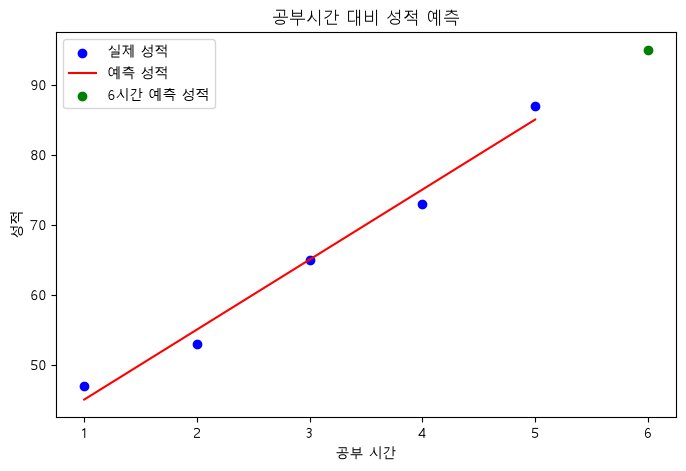

In [6]:
# 학습 데이터에 대한 예측값
y_pred = model.predict(X)
print("학습 데이터에 대한 예측값:", y_pred)

plt.figure(figsize=(8, 5))

# 실제 성적 (산점도)
plt.scatter(X["hours"], y, color="blue", label="실제 성적")

# 예측한 성적 (회귀직선)
plt.plot(X["hours"], y_pred, color="red", label="예측 성적")

# 6시간 학습한 삭생의 예측 성적
plt.scatter(6, predicted_score[0], color="green", label="6시간 예측 성적")

plt.title("공부시간 대비 성적 예측")
plt.xlabel("공부 시간")
plt.ylabel("성적")
plt.legend()
plt.show()

### 모델 평가

In [7]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


# MAE : 오차 절대 평균
# 오차의 크기를 직관적으로 이해
mae = mean_absolute_error(y, y_pred)
print(f"학습데이터에 대한 평균 절대 오차(MAE): {mae:.2f}")

# MSE : 오차 제곱 평균
# 제곱하는 이유는 큰 오차에 대해서 민감하게 반응 ★
mse = mean_squared_error(y, y_pred)
print(f"학습데이터에 대한 평균 제곱 오차(MSE): {mse:.2f}")

# R2 Score : 결정계수
# 모델이 실제 데이터를 얼마만큼 정확한지를 나타내는 지표
# 0 <==> 1
# 음수일 경우 학습 실패
r2 = r2_score(y, y_pred)
print(f"학습데이터에 대한 결정계수(R^2): {r2:.2f}")

학습데이터에 대한 평균 절대 오차(MAE): 1.60
학습데이터에 대한 평균 제곱 오차(MSE): 3.20
학습데이터에 대한 결정계수(R^2): 0.98


---

## 경사하강법 (Gradient Descent)

- 기울기(Weight)        : 10
- 절편(Bias)            : 35
- 6시간 학습            : 96점

### 손실 함수 (Loss Function)

- 모델이 예측한 값이 실제 정답과 얼마나 차이가 나는지를 수치로 표현하는 함수
- MSE 를 대표적으로 사용

### 학습 데이터 준비

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

# 배치 하강법 (BGD) : 전체 데이터를 사용, 시간, 리소스 많이 사용
# 확률적 경사하강법 (SGD) : 확률적을 1개의 데이터를 추출해서 하강 방법
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# 학습 데이터 생성
df = pd.DataFrame({
    "hours": [1, 2, 3, 4, 5],
    "scores": [ 47, 53, 65, 73, 87]
})

# 독립변수 (입력번수: Feature)
X = df[["hours"]]
# 종속변수 (정답 : Target)
y = df["scores"]

df

,hours,scores
0,1,47
1,2,53
2,3,65
3,4,73
4,5,87


In [9]:
# 선형회귀
model = LinearRegression()
# 모델 학습
model.fit(X, y)
# 예측값
y_pred = model.predict(X)
# 결과값 : 경사하강법으로 도달하려는 목표
print(f"Weight: {model.coef_[0]:.2f}")
print(f"Bias: {model.intercept_:.2f}")
print(f"MSE: {mean_squared_error(y, y_pred):.4f}")

Weight: 10.00
Bias: 35.00
MSE: 3.2000


### 확률적 경사하강법 모델 생성
- SGDRegressor 모델 생성
- SGD(Stochastic Gradient Descent)

In [10]:
sgd = SGDRegressor(
    loss="squared_error",        # 제곱 오차 기반 손실함수
    learning_rate="constant",    # 학습률을 일정하게 유지
    eta0=0.01,                   # 초기 학습률
    max_iter=1000,               # 학습 횟수 fit() 반복 회수
    shuffle=False,               # 학습 데이터 섞지 않음
    random_state=42              # 난수 시드 설정
)

In [11]:
# 전체 데이터를 기준으로 총 몇회 반복 할 것인가?
epochs = 1000

# 학습 과정을 저장하는 리스트
history = []

for epochs in range(epochs):
    # 전체 데이터 1회 학습 (1 epoch)
    sgd.partial_fit(X, y)

    # 1회 학습 후 예측
    y_pred = sgd.predict(X)

    # 현재 모델의 MSE 계산
    mse = mean_squared_error(y, y_pred)

    # 현재 학습 결과 저장(누적)
    history.append({
        "epoch": epochs + 1,
        "weight": sgd.coef_[0],
        "bias": sgd.intercept_[0],
        "mse": mse
    })

# 학습 기록 => DataFrame 으로 변환
history_df = pd.DataFrame(history)
history_df

,epoch,weight,bias,mse
0,1,8.455225,2.731163,1369.816039
1,2,12.813586,4.270770,515.808449
2,3,15.045308,5.190714,269.417813
3,4,16.173242,5.787904,193.744630
4,5,16.728403,6.216494,167.673523
...,...,...,...,...
995,996,10.129378,34.741070,3.250171
996,997,10.129367,34.741113,3.250168
997,998,10.129357,34.741155,3.250165
998,999,10.129346,34.741197,3.250162


In [12]:
# history_df[ 조건 ]
# history_df[ "history_df["epoch"].isin([1,5,10,50,100,300,500,1000])" ] => "○○○○" 이곳에 들어가는게 조건이다.

history_df[ history_df["epoch"].isin([1,5,10,50,100,300,500,1000]) ]

,epoch,weight,bias,mse
0,1,8.455225,2.731163,1369.816039
4,5,16.728403,6.216494,167.673523
9,10,17.060518,7.615610,141.377004
49,50,15.031795,15.629821,72.111791
99,100,13.294764,22.401342,32.278720
299,300,10.678818,32.599172,4.254356
499,500,10.223895,34.372614,3.302220
999,1000,10.129335,34.741238,3.250159


## 손실함수 차트

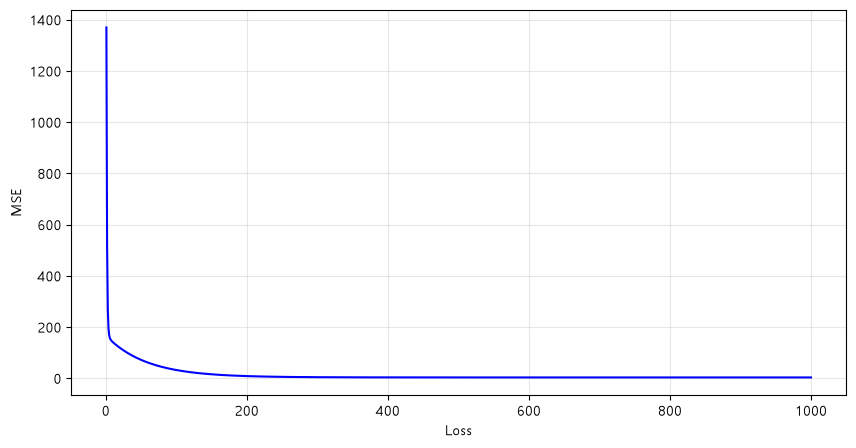

In [13]:
plt.figure(figsize=(10,5))

# Epoch에 따른 MSE 변화
plt.plot(
    history_df["epoch"],
    history_df["mse"],
    color="blue",
    label="학습 손실(Traing Loss)"
)

plt.xlabel("Loss")
plt.ylabel("MSE")
plt.grid(alpha=0.3)
plt.show()

### 기울기와 절편 변화 시각화

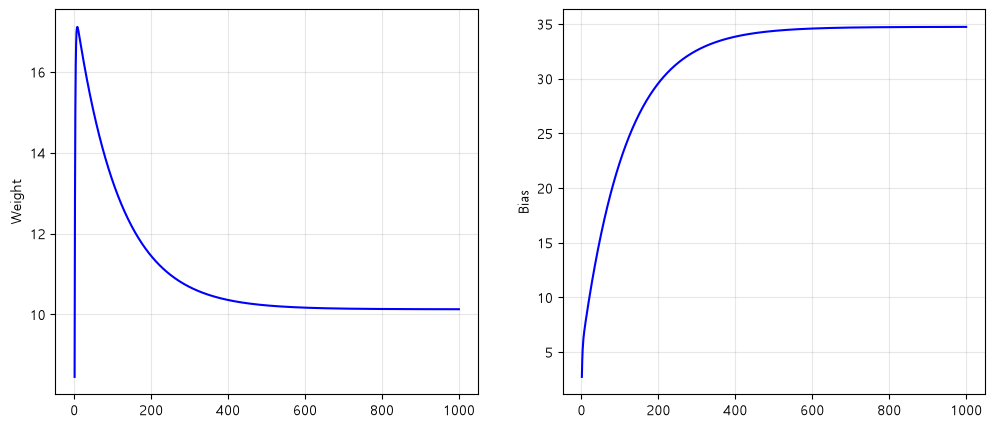

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 기울기 변화
axes[0].plot(
    history_df["epoch"],
    history_df["weight"],
    color="blue",
)
axes[0].grid(alpha=0.3)
axes[0].set_ylabel("Weight")

# 절편 변화
axes[1].plot(
    history_df["epoch"],
    history_df["bias"],
    color="blue"
)
axes[1].grid(alpha=0.3)
axes[1].set_ylabel("Bias")

plt.show()

### 최종 모델로 시험 적적 예측하기

In [15]:
# 최종 학습된 기울기, 절편
print(f"기울기(w): {sgd.coef_[0]:.2f}")
print(f"절편(b): {sgd.intercept_[0]:.2f}")

# 6시간 학습한 학생
new_data = pd.DataFrame({"hours": [6]})

# 경사하강법으로 학습한 모델로 예측
prediction = sgd.predict(new_data)

print(f"예측 성적: { prediction[0]:.2f}점")

기울기(w): 10.13
절편(b): 34.74
예측 성적: 95.52점


---

## 다중 선형회귀 (Multiple Linear Regression)

### 라이브러리 임포트 및 데이터 준비

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# 데이터 생성
df = pd.DataFrame({
    "study_hours":    [1, 2, 3, 4, 5, 2, 3, 5, 4, 1],
    "sleep_hours":    [6, 8, 5, 7, 8, 5, 8, 6, 6, 8],
    "practice_count": [10, 15, 20, 25, 30, 12, 28, 22, 32, 8],
    "score":          [47, 58, 60, 76, 87, 49, 73, 77, 79, 52]
})

df

,study_hours,sleep_hours,practice_count,score
0,1,6,10,47
1,2,8,15,58
2,3,5,20,60
3,4,7,25,76
4,5,8,30,87
5,2,5,12,49
6,3,8,28,73
7,5,6,22,77
8,4,6,32,79
9,1,8,8,52


### 상관계수 확인 (차트)

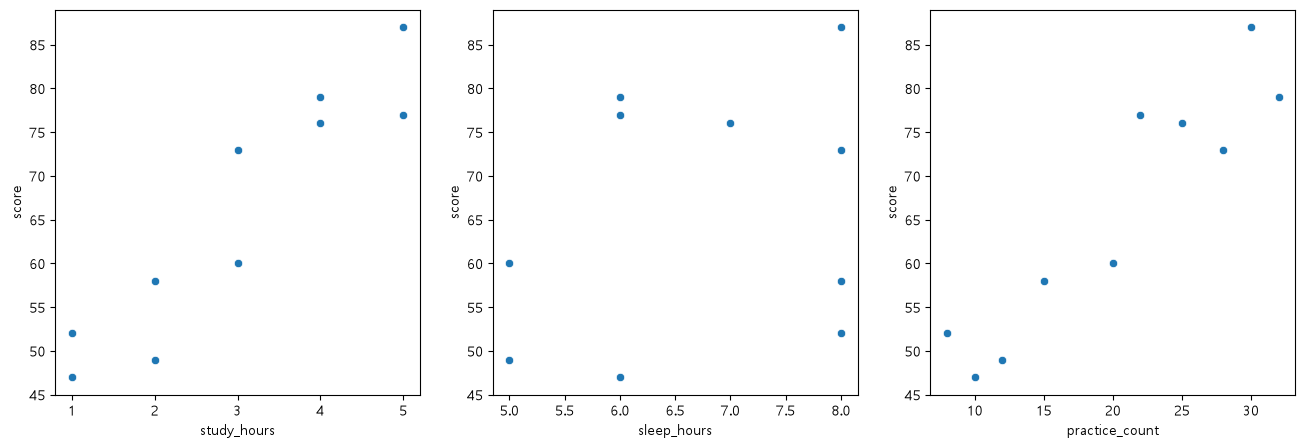

In [29]:
# 1행 3열의 그래프 영역 생성
fig, axes = plt.subplots(1, 3, figsize=(16,5))

# 공부시간 + 성적
sns.scatterplot(
    data=df,
    x="study_hours",
    y="score",
    ax=axes[0]
)
# 수면시간 + 성적
sns.scatterplot(
    data=df,
    x="sleep_hours",
    y="score",
    ax=axes[1]
)
# 문제풀이 개수 + 성적
sns.scatterplot(
    data=df,
    x="practice_count",
    y="score",
    ax=axes[2]
)

plt.show()

### 상관계수 확인

c:\Users\miro2\kant_study\03_ML\kant_ml\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
c:\Users\miro2\kant_study\03_ML\kant_ml\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


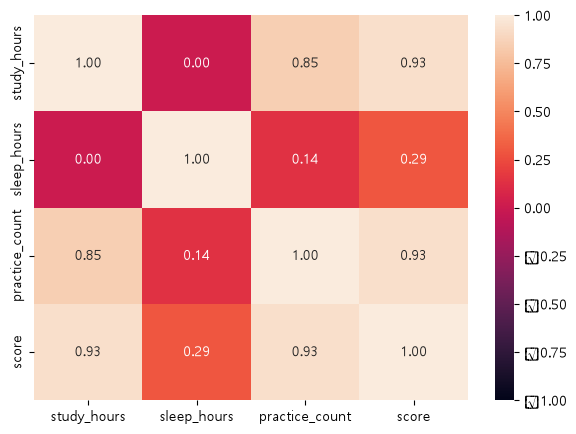

In [30]:
# 모든 컬럼 사이의 상관계수 확인
corr = df.corr()

plt.figure(figsize=(7,5))

sns.heatmap(
    corr,
    annot=True,     # 상관계수 표시
    vmin=-1,        # 최소값
    vmax=1,         # 최대값
    fmt=".2f"       # 소수점 두자리
)

plt.show()

### 입력 데이터(X)와 정답데이터(y) 분리

In [31]:
# 복수개의 입력데이터
features = ["study_hours", "sleep_hours", "practice_count"]

# 입력 데이터 (2차원)
X = df[features]
# 정답데이터 (1차원)
y = df["score"]


# 뎅터 차원 확인
print(X.shape)
print(y.shape)

(10, 3)
(10,)


### 다중 선형회귀 모델 생성 , 학습

In [32]:
# 다중 선형회귀 모델 객체 생성
model = LinearRegression()

# 입력 데이터 3, 출력 데이터 1 사용해서 연습
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[5.8 ,2.68,0.63]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['study_hours','sleep_hours','practice_count']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,17.66
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


### 학습된 가중치(wieght)와 절편(bias) 확인
- coef_=>1      # 1개 결과      # 갯수가 1개가 리턴이 됨
- coef_=>3      # 3개 결과      # 갯수가 3개가 리턴이 됨

In [33]:
print("가중치", model.coef_)
print("절편", model.intercept_)

가중치 [5.80222725 2.68100001 0.63219852]
절편 17.66020808020665


### 가중치 시각화

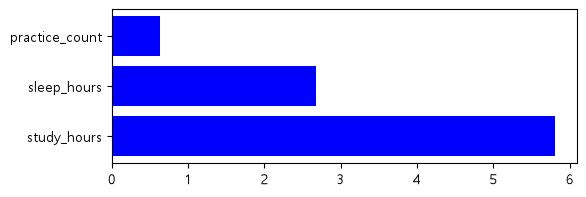

In [34]:
# 입력변수(독립변수, Feature)와 가중치(기울기, Weight) DataFrame으로 생성
coef_df = pd.DataFrame({
    "feature": features,
    "weight": model.coef_
})

# coef_df

plt.figure(figsize=(6, 2))

# 가로바 막대 그래프
plt.barh(
    coef_df["feature"],     # 세로축에 표시
    coef_df["weight"],
    color="blue"
)
plt.show()

### 새로운 학생의 데이터로 예측
- 공부시간 : 4시간
- 수면시간 : 7시간
- 문제풀이 : 30개

In [35]:
# 새로운 데이터 생성
new_data = pd.DataFrame({
    "study_hours": [4],
    "sleep_hours": [7],
    "practice_count": [30]
})

# 학슴한 모델로 시험 성적 예측
prediction = model.predict(new_data)

# 예측 결과
print(f"예측 성적: {prediction[0]:.2f}점")

예측 성적: 78.60점


In [36]:
# 5.80222725 2.68100001 0.63219852
# 17.66

# (4 * 5.80222725) + (7 * 2.68100001) + (30 * 0.63219852) + 17.66

x1 = 4
x2 = 7
x3 = 30

# 학습된 가중치(기울기)
w1, w2, w3 = model.coef_
# 학습된 절편(편향, Bias)
b = model.intercept_

# 회귀공식에 대입
result = w1 * x1 + w2 * x2 + w3 * x3 + b

print(f"직접 계산: {result:.4f}")
print(f"predict 계산: {prediction[0]:.4f}")

직접 계산: 78.6021
predict 계산: 78.6021


### 실제 성적과 예측한 성적의 오차 비교

In [37]:
# 전체 학습 데이터에 대한 예측값
y_pred = model.predict(X)
y_pred

# 실제 값하고 예측값을 비교하기 위해 복사본 생성
result_df = df.copy()

# 없는 열을 명시면 자동으로 추가된다.
result_df["예측값"] = y_pred
# 오차 계산 새로운 열로 추가
result_df["예측 오차"] = y - y_pred

result_df.round(2)

,study_hours,sleep_hours,practice_count,score,예측값,예측 오차
0,1,6,10,47,45.87,1.13
1,2,8,15,58,60.20,-2.20
2,3,5,20,60,61.12,-1.12
3,4,7,25,76,75.44,0.56
4,5,8,30,87,87.09,-0.09
5,2,5,12,49,50.26,-1.26
6,3,8,28,73,74.22,-1.22
7,5,6,22,77,76.67,0.33
8,4,6,32,79,77.19,1.81
9,1,8,8,52,49.97,2.03


### 모델 평가

In [38]:
# 오차 절대 평균 (MAE)
mae = mean_absolute_error(y, y_pred)
# 오차 제곱 평균 (MSE)
mse = mean_squared_error(y, y_pred)
# R2 score 결정계수
r2 = r2_score(y, y_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"R2: {r2:.4f}")

MAE: 1.1739
MSE: 1.8252
R2: 0.9900


### 학습 데이터와 데스트 데이터 분리

![트레인테스트](./images/train_test.png)

In [44]:
# 학습 데이터와 테스트 데이터 분리
# x_train, X_test, y_train, y_test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("y_train", y_train.shape)
print("y_test", y_test.shape)

X_train (7, 3)
X_test (3, 3)
y_train (7,)
y_test (3,)


### 모델 학습

In [45]:
test_model = LinearRegression()
# 70% 데이터로 학습
test_model.fit(X_train, y_train)
# 학습하지 않은 데이터로 결과 예측
test_pred = test_model.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, test_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, test_pred):.4f}")
print(f"R2: {r2_score(y_test, test_pred):.4f}")

MAE: 3.0870
MSE: 10.6380
R2: 0.9327


### 특성 스케일링(Feature Scaling)
- 서로 다른 단위 또는 크기를 가진 데이터를 비슷한 척도로 변환하는 전처리 과정

![피처스케일링](./images/feature_scaling.png)

In [ ]:
# describe() : 기초적인 통계 수치 확인
X.describe().round(2)

,study_hours,sleep_hours,practice_count
count,10.00,10.00,10.00
mean,3.00,6.70,20.20
std,1.49,1.25,8.63
min,1.00,5.00,8.00
25%,2.00,6.00,12.75
50%,3.00,6.50,21.00
75%,4.00,8.00,27.25
max,5.00,8.00,32.00


### StandardScaler (스탠다드 스케일러)

![스탠다드스케일러](./images/standardscaler.png)

In [48]:
from sklearn.preprocessing import StandardScaler

# 표준화 객체 생성
scaler = StandardScaler()

# 학습 데이터에대해 평균, 표준편차를 계산하고 데이터를 표준화(-1 ~ 0 ~ +1)
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=features
)

scaled_df.round(2)

,study_hours,sleep_hours,practice_count
0,-1.38,-0.76,-1.32
1,1.20,-0.76,0.20
2,-0.09,-1.65,-0.05
3,-1.38,1.02,-1.58
4,1.20,1.02,1.21
5,0.55,0.13,0.58
6,-0.09,1.02,0.96


### 경사하강법을 이용한 다중 선형회귀
- SGDRegressor 사용
- 입력변수 3개, 출력변수 1개

In [49]:
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(
    loss="squared_error",           # MSE 손실함수
    learning_rate="constant",       # 일정하게 학습
    eta0=0.01,                      # 초기 학습률
    max_iter=3000,                  # 최대 Epoch 횟수
    random_state=42                 # 난수 발생 seed
)

# 표준화된 학습 데이터(70%)로 모델 학습
sgd.fit(X_train_scaled, y_train)

# 표준화된 검증 데이터(30%)로 모델 예측
sgd_pred = sgd.predict(X_test_scaled)

# 모델 평가
print(f"MAE: {mean_absolute_error(y_test, sgd_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, sgd_pred):.4f}")
print(f"R2: {r2_score(y_test, sgd_pred):.4f}")

MAE: 2.8169
MSE: 8.5966
R2: 0.9456


In [52]:
sgd = SGDRegressor(
    loss="squared_error",           # MSE 손실함수
    learning_rate="constant",       # 일정하게 학습
    eta0=0.01,                      # 초기 학습률
    random_state=42                 # 난수 발생 seed
)

history = []

# 500 Epoch 학습
for epoch in range(500):
    # 1 Epoch 한번 학습
    sgd.partial_fit(X_train_scaled, y_train)
    pred = sgd.predict(X_train_scaled)

    history.append({
        "epoch": epoch + 1,
        "w1": sgd.coef_[0],
        "w2": sgd.coef_[1],
        "w3": sgd.coef_[2],
        "bias": sgd.intercept_[0],
        "mse": mean_squared_error(y_train, pred)
    })

history_df = pd.DataFrame(history)
history_df.tail()

,epoch,w1,w2,w3,bias,mse
495,496,9.924025,3.620886,3.290704,67.424572,0.144615
496,497,9.924418,3.620984,3.290298,67.424569,0.144605
497,498,9.924807,3.621080,3.289895,67.424567,0.144594
498,499,9.925193,3.621176,3.289496,67.424564,0.144584
499,500,9.925575,3.621271,3.289101,67.424562,0.144573


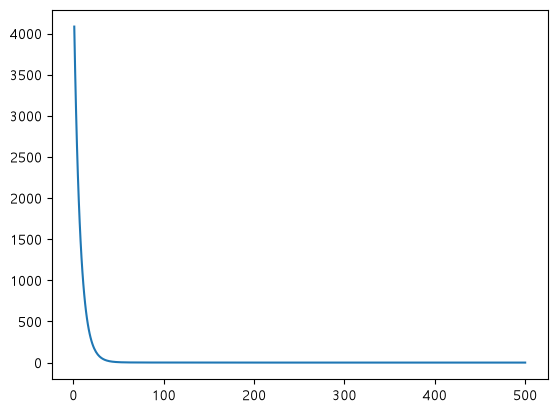

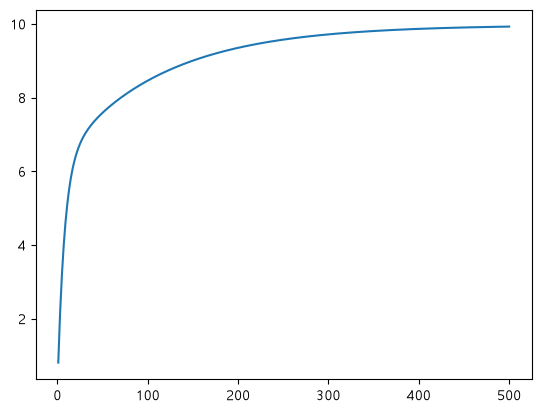

In [55]:
# 손실곡선
# X = epoch
# y = mse
# plot

plt.plot(
    history_df["epoch"],
    history_df["mse"]
)
plt.show()

# w1 가중치 차트
# X = epoch

plt.plot(
    history_df["epoch"],
    history_df["w1"]
)
plt.show()

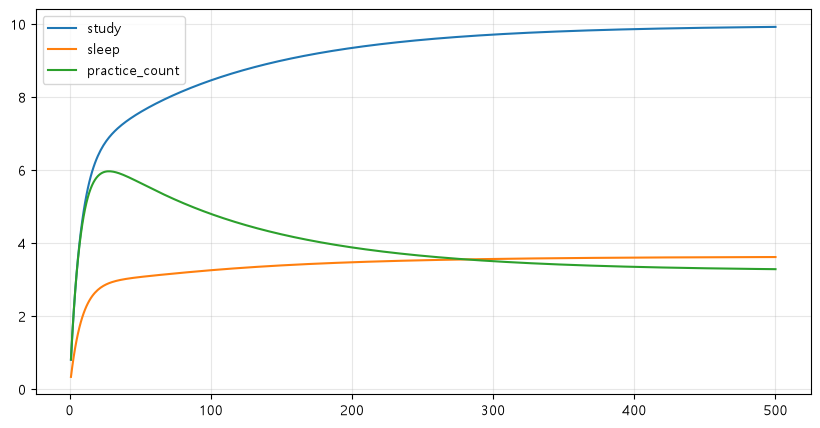

In [63]:
fig, axe = plt.subplots(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["w1"],
    label="study"
)
plt.plot(
    history_df["epoch"],
    history_df["w2"],
    label="sleep"
)
plt.plot(
    history_df["epoch"],
    history_df["w3"],
    label="practice_count"
)
plt.legend()
plt.grid(alpha=0.3)
plt.show()